# Paso 6 · Análisis exploratorio de datos (EDA)

**Objetivo:** entender el dataset de Lending Club antes de interpretar los modelos: calidad de los datos, distribución de las variables, y cómo se relacionan con el incumplimiento (`default`).

**Contenido:** (1) carga, (2) valores faltantes, (3) variable objetivo, (4) análisis univariado, (5) análisis bivariado, (6) resumen ejecutivo.

Se explora el **conjunto completo de préstamos cerrados** (Fully Paid + Charged Off). Para evitar fuga de información, las decisiones de preprocesamiento del modelado se tomaron solo con `train`; aquí se describe el panorama general sin ajustar nada.

## 1. Carga

In [1]:
import os, glob, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass

RUTA = '/content/drive/MyDrive/ML_LendingClub'   # <- ajusta si tu carpeta se llama distinto
DIR_OUT = RUTA + '/resultados_eda'; os.makedirs(DIR_OUT, exist_ok=True)

candidatos = [f for f in glob.glob(RUTA + '/**/accepted_2007_to_2018Q4.csv', recursive=True) if os.path.isfile(f)]
if not candidatos:
    candidatos = sorted(f for f in glob.glob(RUTA + '/*accepted*') if os.path.isfile(f))
archivo = candidatos[0]; print('Archivo:', archivo)

t0 = time.time()
bruto = pd.read_csv(archivo, low_memory=False)
print(f'Dataset completo: {bruto.shape[0]:,} filas x {bruto.shape[1]} columnas ({time.time()-t0:.0f} s)')

Mounted at /content/drive
Archivo: /content/drive/MyDrive/ML_LendingClub/accepted_2007_to_2018q4.csv/accepted_2007_to_2018Q4.csv
Dataset completo: 2,260,701 filas x 151 columnas (67 s)


## 2. Valores faltantes (todas las columnas del archivo original)

Columnas con >50 % de faltantes: 44 de 151
Columnas sin faltantes: 1


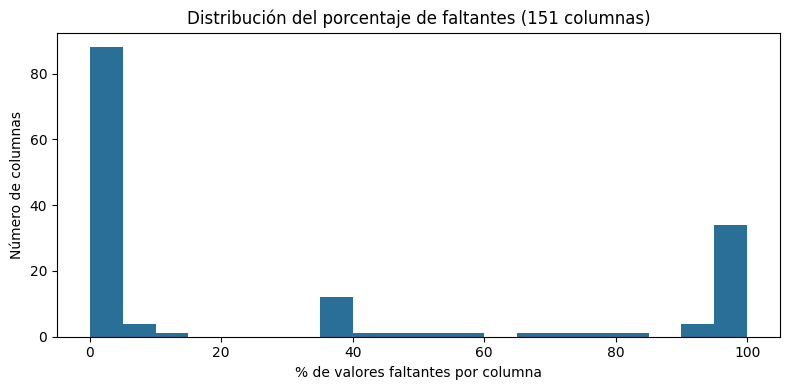

,% faltante
member_id,100.0
orig_projected_additional_accrued_interest,99.6
hardship_reason,99.5
hardship_payoff_balance_amount,99.5
hardship_last_payment_amount,99.5
payment_plan_start_date,99.5
hardship_type,99.5
hardship_status,99.5
hardship_start_date,99.5
deferral_term,99.5


In [2]:
nulos = (bruto.isna().mean() * 100).sort_values(ascending=False)
print('Columnas con >50 %% de faltantes: %d de %d' % ((nulos > 50).sum(), len(nulos)))
print('Columnas sin faltantes: %d' % (nulos == 0).sum())
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(nulos, bins=20, color='#2a6f97'); ax.set_xlabel('% de valores faltantes por columna'); ax.set_ylabel('Número de columnas')
ax.set_title('Distribución del porcentaje de faltantes (151 columnas)')
plt.tight_layout(); plt.savefig(DIR_OUT + '/faltantes_hist.png', dpi=150); plt.show()
nulos.head(15).round(1).to_frame('% faltante')

## 3. Población de estudio y variable objetivo
Solo los préstamos con desenlace conocido: `Fully Paid` (default=0) y `Charged Off` (default=1). Se excluyen los vigentes, en mora y los de la categoría *Does not meet the credit policy*, porque su desenlace final aún no se conoce o pertenecen a otra política. **No es un muestreo**: es la definición del problema.

                                                          n
loan_status                                                
Fully Paid                                          1076751
Current                                              878317
Charged Off                                          268559
Late (31-120 days)                                    21467
In Grace Period                                        8436
Late (16-30 days)                                      4349
Does not meet the credit policy. Status:Fully Paid     1988
Does not meet the credit policy. Status:Charged...      761
Default                                                  40

Población de estudio: 1,345,310 préstamos | tasa de default: 19.96 %


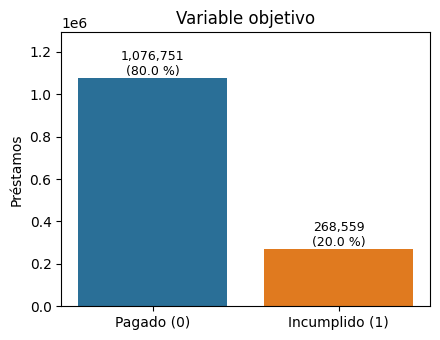

In [3]:
print(bruto['loan_status'].value_counts().to_frame('n'))
df = bruto[bruto['loan_status'].isin(['Fully Paid', 'Charged Off'])].copy()
df['default'] = (df['loan_status'] == 'Charged Off').astype(int)
del bruto
print(f'\nPoblación de estudio: {len(df):,} préstamos | tasa de default: {df.default.mean()*100:.2f} %')
fig, ax = plt.subplots(figsize=(4.5, 3.5))
c = df['default'].value_counts().sort_index()
ax.bar(['Pagado (0)', 'Incumplido (1)'], c.values, color=['#2a6f97', '#e07a1f']); ax.set_ylabel('Préstamos')
for i, v in enumerate(c.values): ax.text(i, v, f'{v:,}\n({v/len(df)*100:.1f} %)', ha='center', va='bottom', fontsize=9)
ax.set_ylim(0, c.max() * 1.2); ax.set_title('Variable objetivo')
plt.tight_layout(); plt.savefig(DIR_OUT + '/objetivo.png', dpi=150); plt.show()

## 4. Análisis univariado

In [4]:
NUM = ['loan_amnt', 'int_rate', 'installment', 'annual_inc', 'dti', 'fico_range_high', 'delinq_2yrs',
       'inq_last_6mths', 'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc', 'mort_acc', 'pub_rec_bankruptcies']
CAT = ['purpose', 'home_ownership', 'addr_state', 'verification_status']
df['term_meses'] = df['term'].str.extract(r'(\d+)')[0].astype(float)
df['emp_length_anios'] = df['emp_length'].str.extract(r'(\d+)')[0].astype(float)
df.loc[df['emp_length'] == '< 1 year', 'emp_length_anios'] = 0.0
NUMX = NUM + ['term_meses', 'emp_length_anios']

desc = df[NUMX].describe(percentiles=[.01, .25, .5, .75, .99]).T
desc['faltantes_%'] = df[NUMX].isna().mean() * 100
desc['asimetria'] = df[NUMX].skew()
desc.round(2)

,count,mean,std,min,1%,25%,50%,75%,99%,max,faltantes_%,asimetria
loan_amnt,1345310.0,14419.97,8717.05,500.00,1500.00,8000.00,12000.00,20000.00,35000.00,40000.00,0.00,0.78
int_rate,1345310.0,13.24,4.77,5.31,5.32,9.75,12.74,15.99,26.30,30.99,0.00,0.71
installment,1345310.0,438.08,261.51,4.93,52.86,248.48,375.43,580.73,1221.50,1719.83,0.00,1.01
annual_inc,1345310.0,76247.64,69925.10,0.00,18000.00,45780.00,65000.00,90000.00,250000.00,10999200.00,0.00,46.32
dti,1344936.0,18.28,11.16,-1.00,1.78,11.79,17.61,24.06,38.47,999.00,0.03,27.11
fico_range_high,1345310.0,700.19,31.85,629.00,664.00,674.00,694.00,714.00,804.00,850.00,0.00,1.29
delinq_2yrs,1345310.0,0.32,0.88,0.00,0.00,0.00,0.00,0.00,4.00,39.00,0.00,5.60
inq_last_6mths,1345309.0,0.66,0.94,0.00,0.00,0.00,0.00,1.00,4.00,8.00,0.00,1.70
open_acc,1345310.0,11.59,5.47,0.00,3.00,8.00,11.00,14.00,29.00,90.00,0.00,1.30
pub_rec,1345310.0,0.22,0.60,0.00,0.00,0.00,0.00,0.00,2.00,86.00,0.00,11.56


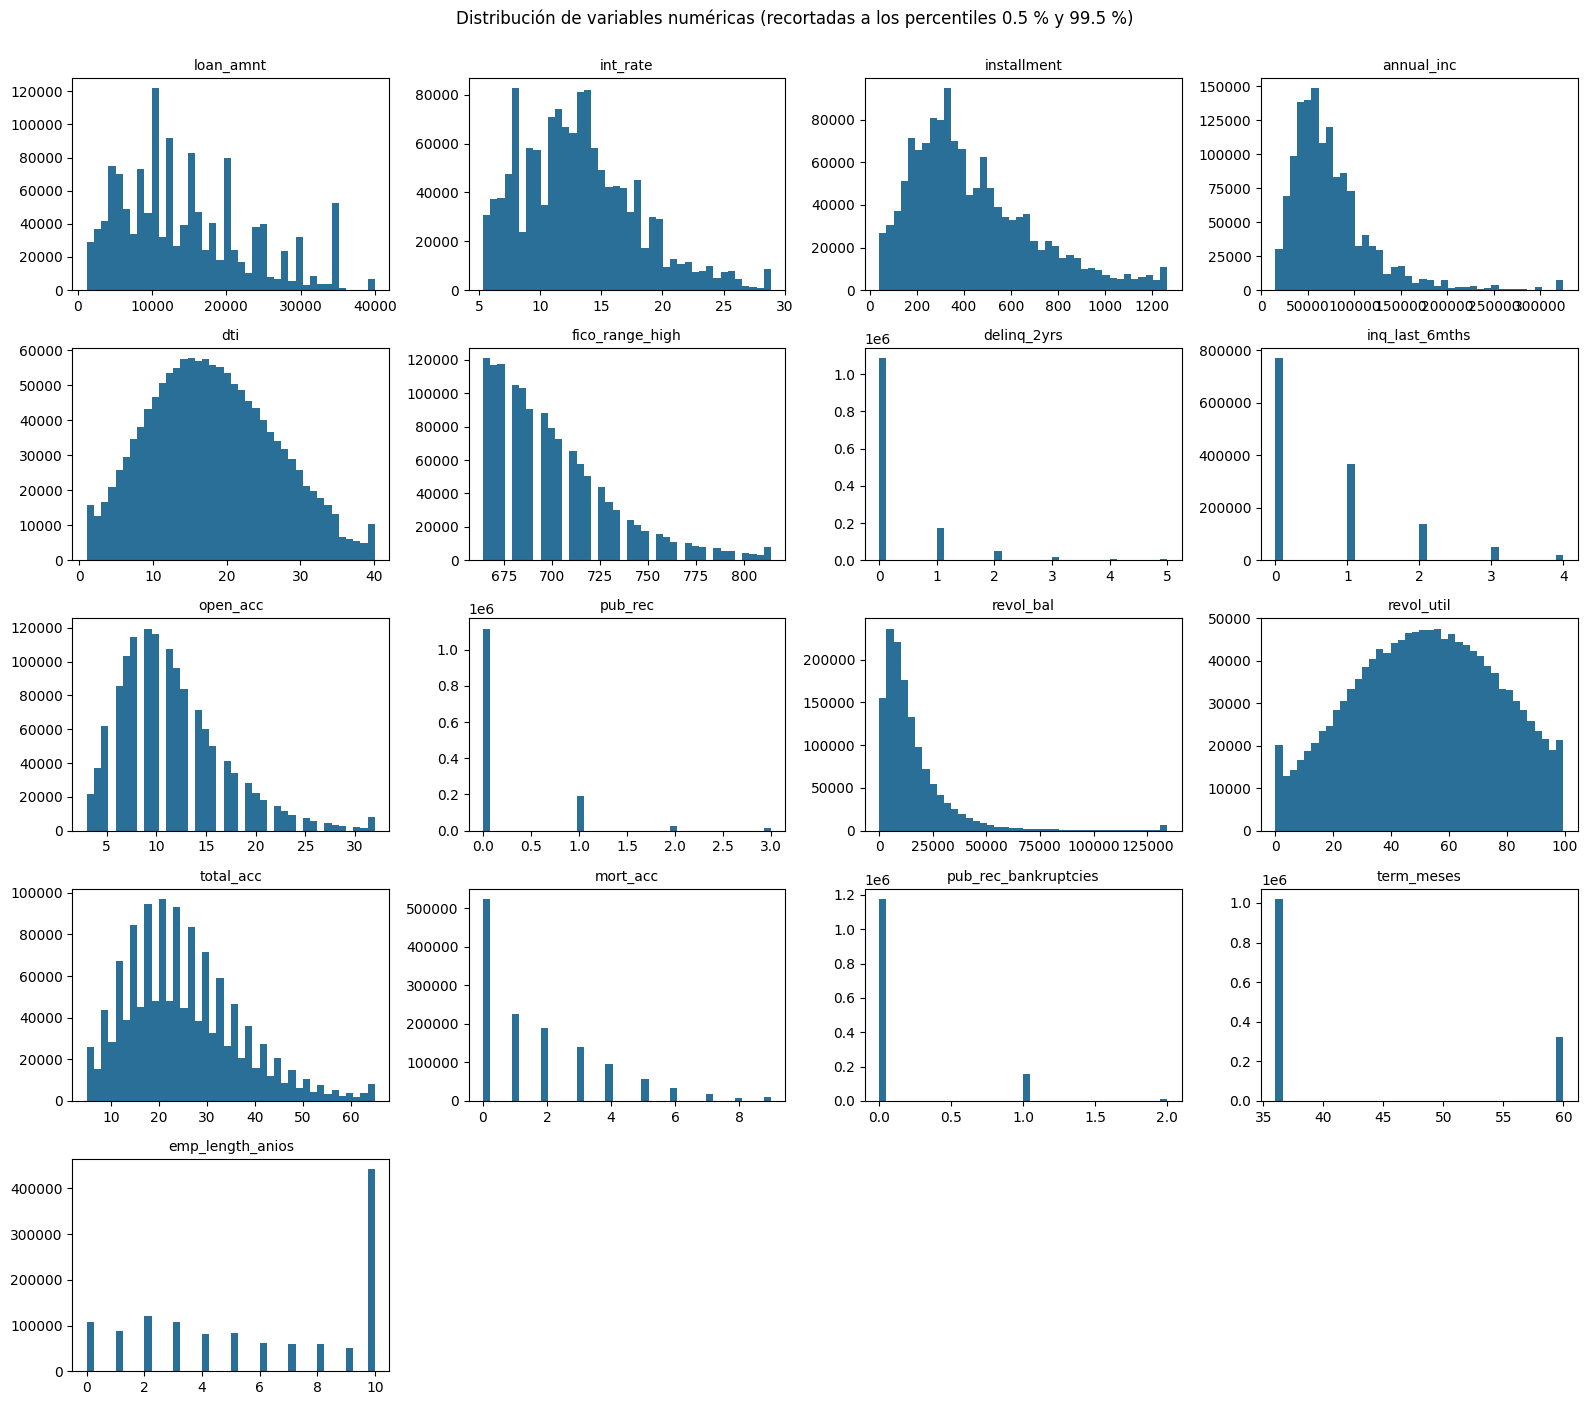

In [5]:
fig, axs = plt.subplots(5, 4, figsize=(16, 14)); axs = axs.ravel()
for a, c in zip(axs, NUMX):
    x = df[c].dropna()
    lo, hi = x.quantile([.005, .995])
    a.hist(x.clip(lo, hi), bins=40, color='#2a6f97'); a.set_title(c, fontsize=10)
for a in axs[len(NUMX):]: a.axis('off')
plt.suptitle('Distribución de variables numéricas (recortadas a los percentiles 0.5 % y 99.5 %)', y=1.0)
plt.tight_layout(); plt.savefig(DIR_OUT + '/univariado_numericas.png', dpi=130); plt.show()

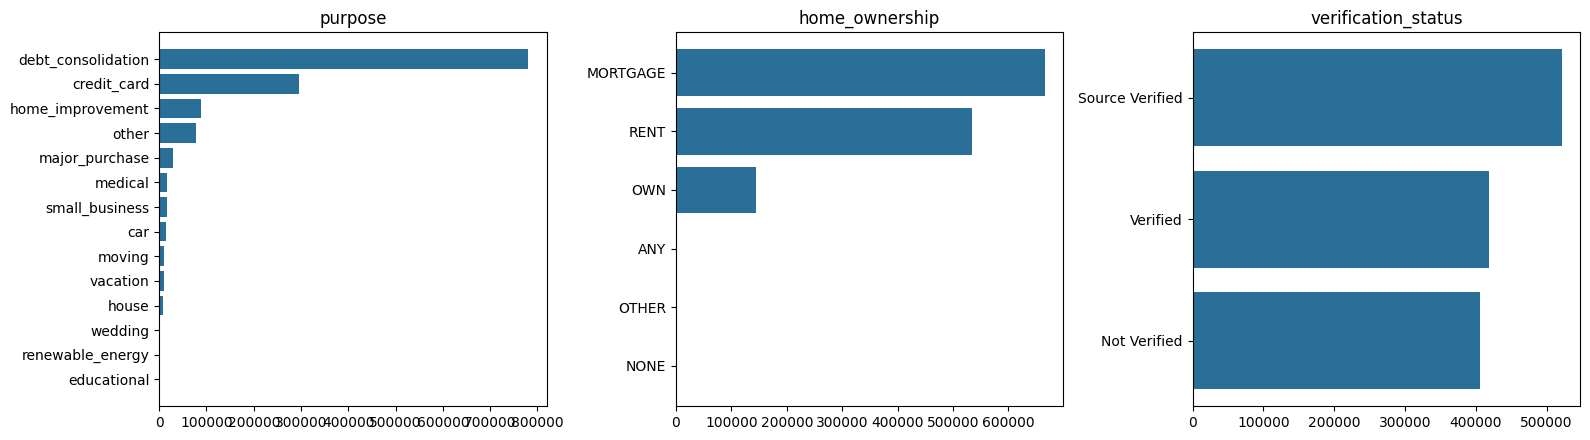

addr_state: 51 estados; los 5 más frecuentes:
addr_state
CA    14.6
TX     8.2
NY     8.2
FL     7.1
IL     3.8


In [6]:
fig, axs = plt.subplots(1, 3, figsize=(16, 4.5))
for a, c in zip(axs, ['purpose', 'home_ownership', 'verification_status']):
    v = df[c].fillna('Desconocido').value_counts()
    a.barh(v.index[::-1], v.values[::-1], color='#2a6f97'); a.set_title(c)
plt.tight_layout(); plt.savefig(DIR_OUT + '/univariado_categoricas.png', dpi=130); plt.show()
print('addr_state: %d estados; los 5 más frecuentes:' % df['addr_state'].nunique())
print((df['addr_state'].value_counts(normalize=True).head(5) * 100).round(1).to_string())

## 5. Análisis bivariado frente a `default`

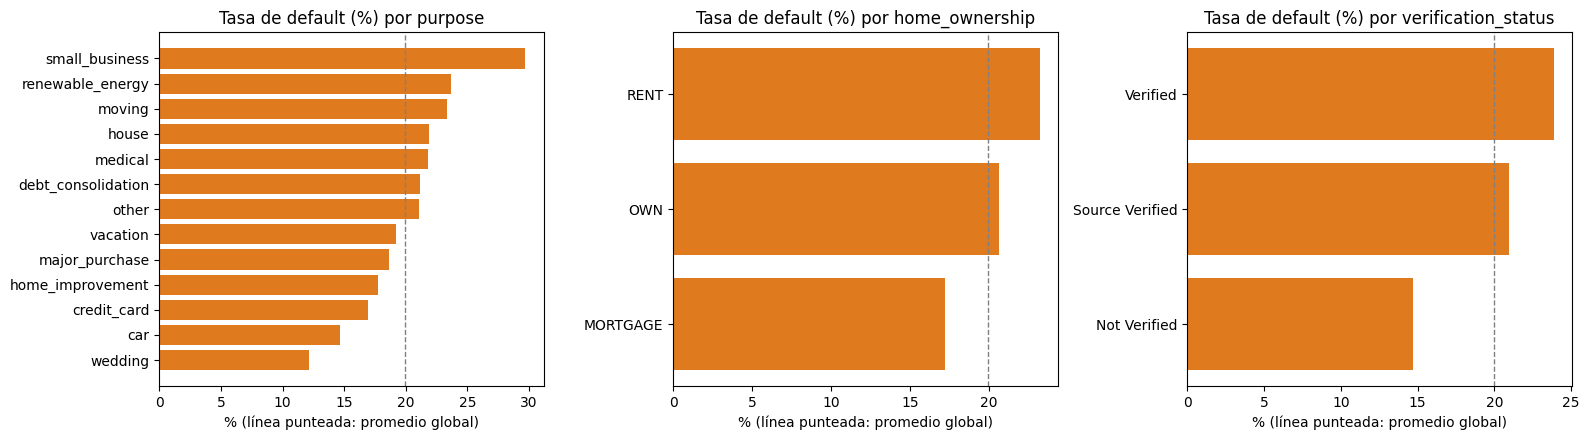

In [7]:
# 5.1 Tasa de default por categoría
fig, axs = plt.subplots(1, 3, figsize=(16, 4.5))
tasa_global = df['default'].mean() * 100
for a, c in zip(axs, ['purpose', 'home_ownership', 'verification_status']):
    g = df.assign(**{c: df[c].fillna('Desconocido')}).groupby(c)['default'].agg(['mean', 'size'])
    g = g[g['size'] >= 500].sort_values('mean')
    a.barh(g.index, g['mean'] * 100, color='#e07a1f'); a.axvline(tasa_global, color='gray', ls='--', lw=1)
    a.set_title(f'Tasa de default (%) por {c}'); a.set_xlabel('% (línea punteada: promedio global)')
plt.tight_layout(); plt.savefig(DIR_OUT + '/bivariado_categoricas.png', dpi=130); plt.show()

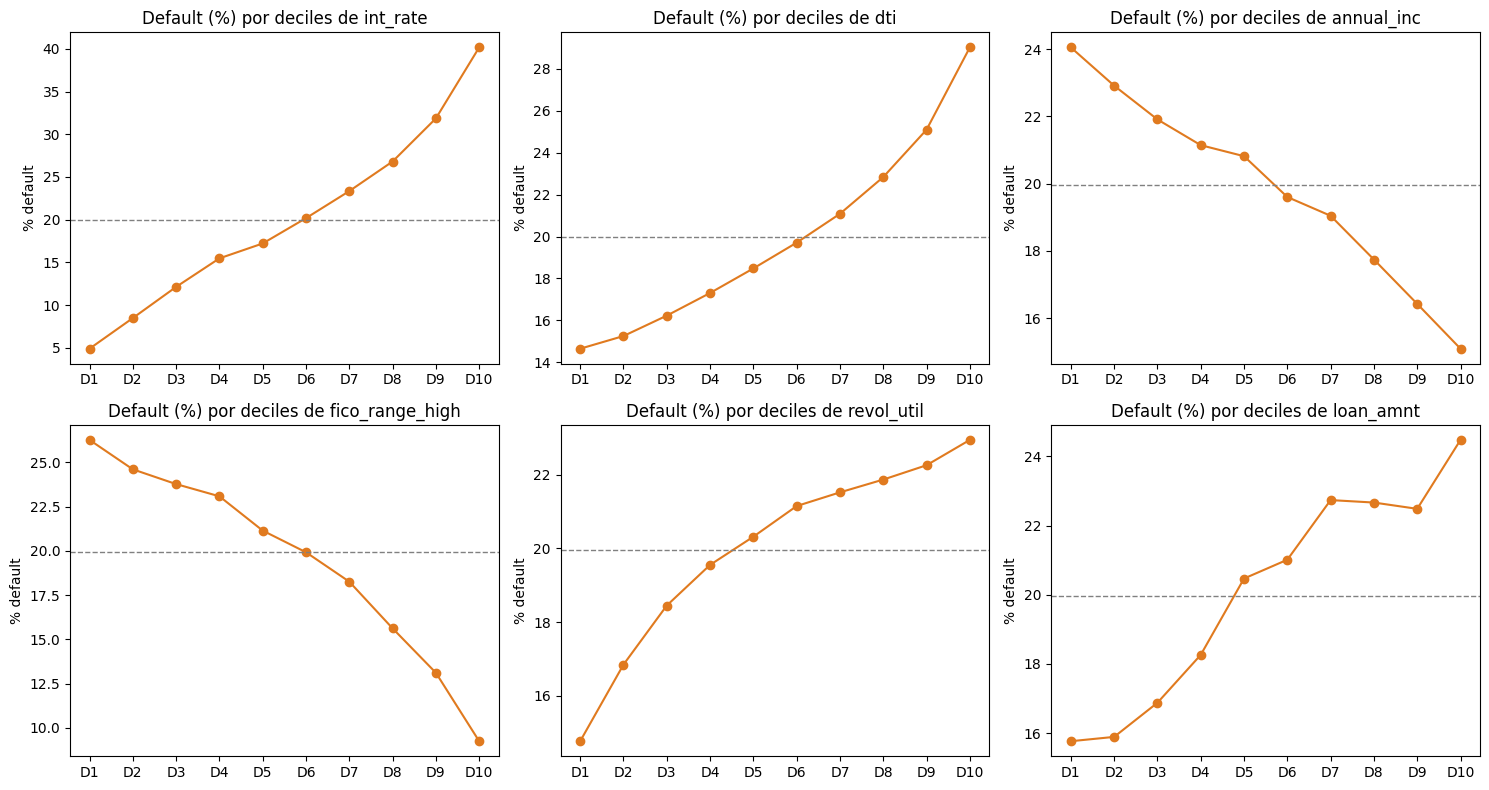

In [8]:
# 5.2 Tasa de default por deciles de las numéricas más relevantes
vars_dec = ['int_rate', 'dti', 'annual_inc', 'fico_range_high', 'revol_util', 'loan_amnt']
fig, axs = plt.subplots(2, 3, figsize=(15, 8)); axs = axs.ravel()
for a, c in zip(axs, vars_dec):
    d = df[[c, 'default']].dropna()
    q = pd.qcut(d[c], 10, duplicates='drop')
    g = d.groupby(q, observed=True)['default'].mean() * 100
    a.plot(range(len(g)), g.values, 'o-', color='#e07a1f'); a.set_xticks(range(len(g)))
    a.set_xticklabels([f'D{i+1}' for i in range(len(g))]); a.axhline(tasa_global, color='gray', ls='--', lw=1)
    a.set_title(f'Default (%) por deciles de {c}'); a.set_ylabel('% default')
plt.tight_layout(); plt.savefig(DIR_OUT + '/bivariado_deciles.png', dpi=130); plt.show()

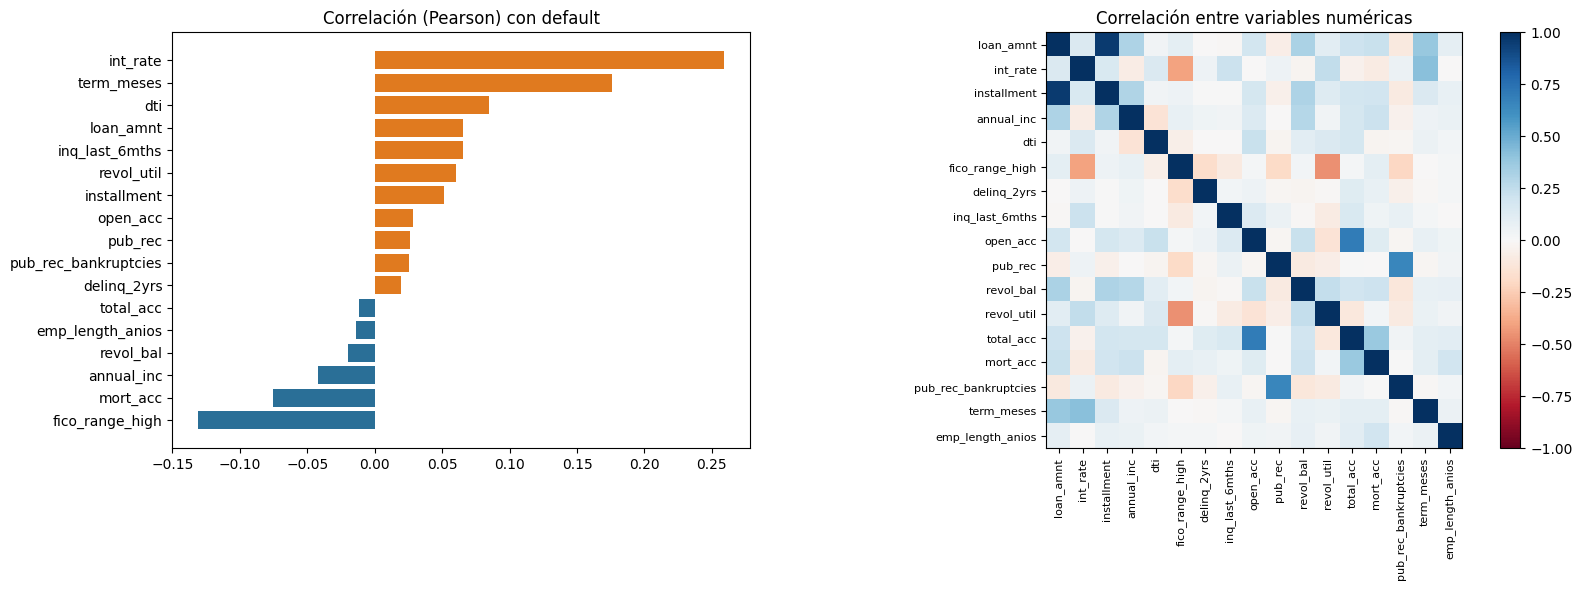

,corr con default
fico_range_high,-0.131
mort_acc,-0.075
annual_inc,-0.042
revol_bal,-0.020
emp_length_anios,-0.014
total_acc,-0.011
delinq_2yrs,0.019
pub_rec_bankruptcies,0.025
pub_rec,0.026
open_acc,0.028


In [9]:
# 5.3 Correlación con el objetivo y entre variables
corr_obj = df[NUMX + ['default']].corr(numeric_only=True)['default'].drop('default').sort_values()
fig, axs = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={'width_ratios': [1, 1.3]})
axs[0].barh(corr_obj.index, corr_obj.values, color=np.where(corr_obj.values > 0, '#e07a1f', '#2a6f97'))
axs[0].set_title('Correlación (Pearson) con default')
C = df[NUMX].corr(numeric_only=True)
im = axs[1].imshow(C.values, cmap='RdBu', vmin=-1, vmax=1)
axs[1].set_xticks(range(len(NUMX))); axs[1].set_xticklabels(NUMX, rotation=90, fontsize=8)
axs[1].set_yticks(range(len(NUMX))); axs[1].set_yticklabels(NUMX, fontsize=8); plt.colorbar(im, ax=axs[1], fraction=0.046)
axs[1].set_title('Correlación entre variables numéricas')
plt.tight_layout(); plt.savefig(DIR_OUT + '/correlaciones.png', dpi=130); plt.show()
corr_obj.round(3).to_frame('corr con default')

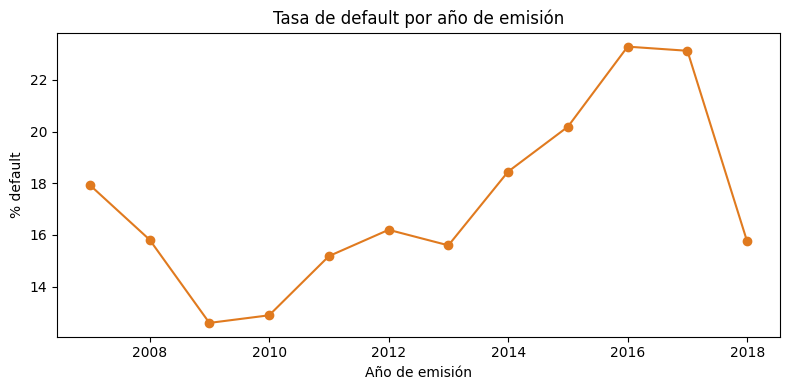

,mean,size
anio,,
2007,0.179,251
2008,0.158,1562
2009,0.126,4716
2010,0.129,11536
2011,0.152,21721
2012,0.162,53367
2013,0.156,134804
2014,0.184,223102
2015,0.202,375545


In [10]:
# 5.4 Evolución temporal (cuidado: los préstamos recientes tienen menos tiempo para incumplir)
df['anio'] = pd.to_datetime(df['issue_d'], format='%b-%Y', errors='coerce').dt.year
g = df.groupby('anio')['default'].agg(['mean', 'size'])
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(g.index, g['mean'] * 100, 'o-', color='#e07a1f'); ax.set_ylabel('% default'); ax.set_xlabel('Año de emisión')
ax.set_title('Tasa de default por año de emisión')
plt.tight_layout(); plt.savefig(DIR_OUT + '/default_por_anio.png', dpi=130); plt.show()
g.round(3)

## 6. Resumen ejecutivo (se calcula con los datos)

In [11]:
tasa = df['default'].mean() * 100
top_corr = corr_obj.reindex(corr_obj.abs().sort_values(ascending=False).index).head(3)
faltantes_modelo = df[NUMX].isna().mean().sort_values(ascending=False).head(3) * 100
g_int = df.groupby(pd.qcut(df['int_rate'], 10, duplicates='drop'), observed=True)['default'].mean() * 100
g_term = df.groupby('term_meses')['default'].mean() * 100
print(f'''RESUMEN EJECUTIVO
- Población: {len(df):,} préstamos cerrados; tasa de default {tasa:.1f} % (clases desbalanceadas, ~1 de cada {1/df.default.mean():.0f}).
- Las tres variables numéricas más correlacionadas con el default: ''' + ', '.join(f'{k} ({v:+.2f})' for k, v in top_corr.items()) + f'''.
- Default por decil de tasa de interés: del decil más bajo ({g_int.iloc[0]:.1f} %) al más alto ({g_int.iloc[-1]:.1f} %).
- El plazo importa: default a 36 meses {g_term.get(36, float('nan')):.1f} %, a 60 meses {g_term.get(60, float('nan')):.1f} %.
- Variables del modelo con más faltantes: ''' + ', '.join(f'{k} ({v:.1f} %)' for k, v in faltantes_modelo.items()) + '''.
- Implicación para el modelado: con clases desbalanceadas conviene usar AUC / AUC-PR y no la exactitud,
  que se vería inflada por la clase mayoritaria. (Interpreta aquí cuán fuertes son las relaciones a la luz de los resultados.)''')

RESUMEN EJECUTIVO
- Población: 1,345,310 préstamos cerrados; tasa de default 20.0 % (clases desbalanceadas, ~1 de cada 5).
- Las tres variables numéricas más correlacionadas con el default: int_rate (+0.26), term_meses (+0.18), fico_range_high (-0.13).
- Default por decil de tasa de interés: del decil más bajo (4.9 %) al más alto (40.2 %).
- El plazo importa: default a 36 meses 16.0 %, a 60 meses 32.4 %.
- Variables del modelo con más faltantes: emp_length_anios (5.8 %), mort_acc (3.5 %), revol_util (0.1 %).
- Implicación para el modelado: con clases desbalanceadas conviene usar AUC / AUC-PR y no la exactitud,
  que se vería inflada por la clase mayoritaria. (Interpreta aquí cuán fuertes son las relaciones a la luz de los resultados.)
